# 04. Strategy Performance, Ablation & Fill-Regime Comparison

This notebook benchmarks our strategy progression on Round 1 **Out-of-Sample (`Day 0`)** and **calibrated Monte Carlo** runs under the explicit assumption $Q_{\max} = 20$:
1. `NoOpBaselineStrategy`: Null control verifying zero leakage.
2. `SymmetricMarketMaker`: Naive symmetric baseline without inventory skewing or bot-wall filtering.
3. `InventorySkewedMarketMaker` (Stage 5): Fixed `half_spread=2.0`, `skew=0.25`, L1 microprice.
4. `Round1Submission` (Stage 6): Bot-wall fair value (`_popular_wall_mid`), alpha-beta drift tracking, penny-improving (`min_edge=1.5`), and reservation skew (`gamma=0.80`).

*Note: All results below are simulated outcomes, not actual competition portal logs.*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.backtesting.engine import BacktestEngine
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.competition.adapter import CompetitionStrategyAdapter
from prosperity_toolkit.data.loader import DataLoader
from prosperity_toolkit.execution.simulator import ExecutionSimulator
from prosperity_toolkit.strategies import (
    InventorySkewedMarketMaker,
    MarketMakingConfig,
    NoOpBaselineStrategy,
    SymmetricMarketMaker,
)
from scripts.evaluate_round0_round1 import _load_round1_trader

loader = DataLoader(data_root=root / "data")
oos_snaps = build_snapshots_from_dataframes(
    loader.load_day_prices(1, 0),
    loader.load_day_trades(1, 0),
)
limits = {"ASH_COATED_OSMIUM": 20, "INTARIAN_PEPPER_ROOT": 20}
cfgs = [
    MarketMakingConfig(symbol="ASH_COATED_OSMIUM", position_limit=20),
    MarketMakingConfig(symbol="INTARIAN_PEPPER_ROOT", position_limit=20),
]

rows = []
qa_curves = {}
for mode in ("conservative", "queue_aware", "touch"):
    strats = [
        NoOpBaselineStrategy(),
        SymmetricMarketMaker(cfgs),
        InventorySkewedMarketMaker(cfgs),
        CompetitionStrategyAdapter(_load_round1_trader(), name="Round1Submission"),
    ]
    for strat in strats:
        sim = ExecutionSimulator(position_limits=limits, fill_mode=mode)
        res = BacktestEngine(simulator=sim).run(strat, oos_snaps)
        lat = round(strat.mean_latency_ms, 4) if isinstance(strat, CompetitionStrategyAdapter) else 0.0
        rows.append({
            "fill_mode": mode,
            "strategy": res.strategy_name,
            "pnl": round(res.total_pnl, 2),
            "max_dd": round(res.max_drawdown, 2),
            "sharpe": round(res.sharpe_ratio, 3),
            "fills": len(res.fills),
            "latency_ms": lat,
        })
        if mode == "queue_aware" and res.strategy_name != "NoOpBaseline":
            qa_curves[res.strategy_name] = res.equity_curve

pd.DataFrame(rows)

,fill_mode,strategy,pnl,max_dd,sharpe,fills,latency_ms
0,conservative,NoOpBaseline,0.0,0.0,0.000,0,0.0000
1,conservative,SymmetricMM,10825.0,886.0,0.500,582,0.0000
2,conservative,InventorySkewedMM,9067.0,837.5,0.403,931,0.0000
3,conservative,Round1Submission,22151.0,267.0,1.188,1001,0.0248
4,queue_aware,NoOpBaseline,0.0,0.0,0.000,0,0.0000
5,queue_aware,SymmetricMM,10825.0,886.0,0.500,582,0.0000
6,queue_aware,InventorySkewedMM,9067.0,837.5,0.403,931,0.0000
7,queue_aware,Round1Submission,22157.0,267.0,1.189,1003,0.0232
8,touch,NoOpBaseline,0.0,0.0,0.000,0,0.0000
9,touch,SymmetricMM,11895.0,913.5,0.550,599,0.0000


## 1. Out-of-Sample Equity Curves & Per-Asset Attribution (`Day 0`, `queue_aware`)

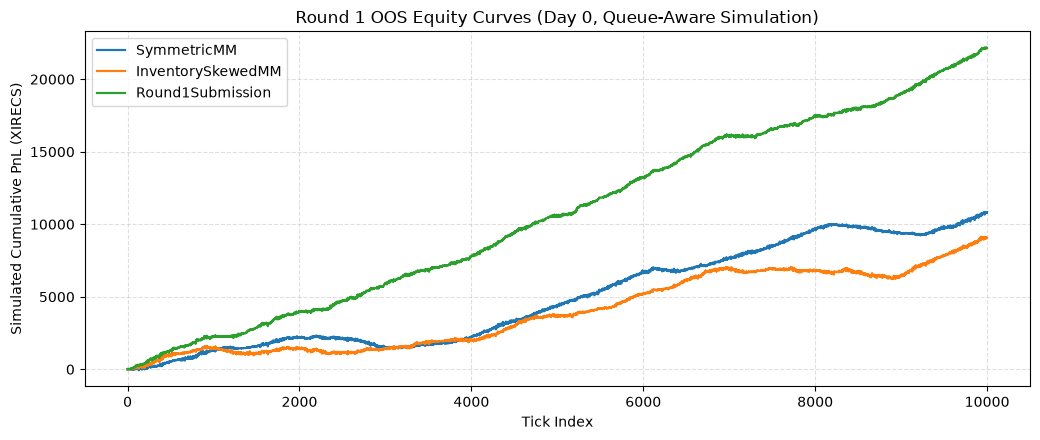

,symbol,simulated_pnl,end_position,total_fills,maker_fills,taker_fills
0,ASH_COATED_OSMIUM,11440.0,13,528,277,251
1,INTARIAN_PEPPER_ROOT,10717.0,0,475,178,297


In [2]:
fig, ax = plt.subplots(figsize=(10.5, 4.5))
for label, curve in qa_curves.items():
    ax.plot(curve, label=label, linewidth=1.6)
ax.set_title("Round 1 OOS Equity Curves (Day 0, Queue-Aware Simulation)")
ax.set_xlabel("Tick Index")
ax.set_ylabel("Simulated Cumulative PnL (XIRECS)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

sim = ExecutionSimulator(position_limits=limits, fill_mode="queue_aware")
sub_res = BacktestEngine(simulator=sim).run(
    CompetitionStrategyAdapter(_load_round1_trader(), name="Round1Submission"),
    oos_snaps,
)
attr = []
for sym in ("ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"):
    sym_fills = [f for f in sub_res.fills if f.symbol == sym]
    cash = sum(-(f.price * f.quantity) for f in sym_fills)
    pos = sum(f.quantity for f in sym_fills)
    last_mid = [s.get_book(sym).mid_price for s in oos_snaps if s.get_book(sym).mid_price is not None][-1]
    attr.append({
        "symbol": sym,
        "simulated_pnl": round(cash + pos * last_mid, 2),
        "end_position": pos,
        "total_fills": len(sym_fills),
        "maker_fills": sum(1 for f in sym_fills if f.fill_type.value == "MAKER"),
        "taker_fills": sum(1 for f in sym_fills if f.fill_type.value == "TAKER"),
    })
pd.DataFrame(attr)